# Global Electronics Retailer — Sales Analysis

## Project Overview

This project analyzes sales data from a global electronics retailer to identify
revenue trends, product performance, sales-channel distribution and geographic
patterns.

The analysis was performed with Python and Pandas, while an interactive dashboard
was developed in Power BI.

### Business Questions

- How has revenue evolved over time?
- Which product categories generate the most revenue?
- Which products perform best in revenue and units sold?
- How does online revenue compare with physical stores?
- Which countries and physical stores generate the most revenue?
- Are there seasonal patterns in sales?
## Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook
- Power BI
- DAX

## Libraries and Data Loading

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"
DOCS_PATH = PROJECT_ROOT / "docs"

In [2]:
print("Current folder:", Path.cwd())
print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_PATH)
print("Sales exists:", (RAW_DATA_PATH / "Sales.csv").exists())

Current folder: /home/luisfelipe/Projeto-Python/analise-vendas/global-electronics-sales-analysis/notebooks
Project root: /home/luisfelipe/Projeto-Python/analise-vendas/global-electronics-sales-analysis
Raw data: /home/luisfelipe/Projeto-Python/analise-vendas/global-electronics-sales-analysis/data/raw
Sales exists: True


In [3]:
sales = pd.read_csv(RAW_DATA_PATH / "Sales.csv")

In [4]:
sales.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD


## Dataset Overview and Data Quality

In [5]:
sales.shape

(62884, 9)

In [6]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Order Number   62884 non-null  int64
 1   Line Item      62884 non-null  int64
 2   Order Date     62884 non-null  str  
 3   Delivery Date  13165 non-null  str  
 4   CustomerKey    62884 non-null  int64
 5   StoreKey       62884 non-null  int64
 6   ProductKey     62884 non-null  int64
 7   Quantity       62884 non-null  int64
 8   Currency Code  62884 non-null  str  
dtypes: int64(6), str(3)
memory usage: 5.2 MB


In [7]:
sales.isnull().sum()

Order Number         0
Line Item            0
Order Date           0
Delivery Date    49719
CustomerKey          0
StoreKey             0
ProductKey           0
Quantity             0
Currency Code        0
dtype: int64

In [8]:
sales["Delivery Date"].isnull().sum()

np.int64(49719)

In [9]:
sales[sales["Delivery Date"].isnull()].head(10)

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
6,366004,1,1/1/2016,NaN,1107461,38,163,6,GBP
7,366004,2,1/1/2016,NaN,1107461,38,1529,2,GBP
8,366005,1,1/1/2016,NaN,844003,33,421,4,EUR
9,366007,1,1/1/2016,NaN,2035771,43,1617,1,USD
10,366007,2,1/1/2016,NaN,2035771,43,666,5,USD
11,366008,1,1/1/2016,NaN,759705,29,1154,9,EUR
12,366008,2,1/1/2016,NaN,759705,29,2510,1,EUR
13,366008,3,1/1/2016,NaN,759705,29,1060,5,EUR
14,366009,1,1/1/2016,NaN,254540,9,1648,1,CAD


In [10]:
sales[sales["Delivery Date"].isnull()]["StoreKey"].value_counts()

StoreKey
9     1577
50    1519
55    1518
54    1498
61    1485
59    1472
45    1471
57    1442
44    1436
65    1395
8     1360
51    1356
64    1353
47    1348
43    1340
66    1295
48    1289
56    1287
53    1284
10    1269
39    1054
40    1050
36    1049
49    1041
38    1034
42    1017
29    1011
37     995
30     976
63     948
5      892
22     800
62     778
27     721
24     703
23     674
19     635
6      615
33     498
32     454
34     448
41     444
20     443
4      431
31     417
21     391
26     295
1      292
15     235
12     224
28     214
16     214
17     210
18     194
13     184
14     126
2       18
Name: count, dtype: int64

In [11]:
sales[sales["Delivery Date"].notnull()]["StoreKey"].value_counts()

StoreKey
0    13165
Name: count, dtype: int64

## Missing Values Analysis

The **Delivery Date** column contains 49,719 missing values.

After investigating the relationship between **Delivery Date** and **StoreKey**, all records with a populated delivery date were associated with **StoreKey = 0**. The dataset documentation and subsequent store analysis indicate that **StoreKey = 0** represents online sales, where a delivery date is expected.

For physical-store transactions, a delivery date is not applicable. Therefore, the missing values in **Delivery Date** are contextually valid and were retained rather than removed.

## Data Dictionary and Duplicate Validation

In [12]:
dictionary = pd.read_csv(
    DOCS_PATH / "Data_Dictionary.csv"
)

In [13]:
dictionary.head(20)

,Table,Field,Description
0,Sales,Order Number,Unique ID for each order
1,Sales,Line Item,Identifies individual products purchased as pa...
2,Sales,Order Date,Date the order was placed
3,Sales,Delivery Date,Date the order was delivered
4,Sales,CustomerKey,Unique key identifying which customer placed t...
5,Sales,StoreKey,Unique key identifying which store processed t...
6,Sales,ProductKey,Unique key identifying which product was purch...
7,Sales,Quantity,Number of items purchased
8,Sales,Currency Code,Currency used to process the order
9,Customers,CustomerKey,Primary key to identify customers


In [14]:
sales.duplicated().sum()

np.int64(0)

In [15]:
sales["Order Number"].duplicated().sum()

np.int64(36558)

## Duplicate Records Analysis

No fully duplicated rows were found in the sales table.

Repeated values in **Order Number** are expected because a single order may contain multiple line items. Therefore, duplicated order numbers do not represent duplicated transactions.

## Data Cleaning

In [16]:
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Delivery Date"] = pd.to_datetime(sales["Delivery Date"])

In [17]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order Number   62884 non-null  int64         
 1   Line Item      62884 non-null  int64         
 2   Order Date     62884 non-null  datetime64[us]
 3   Delivery Date  13165 non-null  datetime64[us]
 4   CustomerKey    62884 non-null  int64         
 5   StoreKey       62884 non-null  int64         
 6   ProductKey     62884 non-null  int64         
 7   Quantity       62884 non-null  int64         
 8   Currency Code  62884 non-null  str           
dtypes: datetime64[us](2), int64(6), str(1)
memory usage: 4.5 MB


In [18]:
## Product Data Preparation

In [19]:
products = pd.read_csv(RAW_DATA_PATH / "Products.csv")

In [20]:
products.head()

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,$6.62,$12.99,101,MP4&MP3,1,Audio
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,$6.62,$12.99,101,MP4&MP3,1,Audio
2,3,Contoso 1G MP3 Player E100 White,Contoso,White,$7.40,$14.52,101,MP4&MP3,1,Audio
3,4,Contoso 2G MP3 Player E200 Silver,Contoso,Silver,$11.00,$21.57,101,MP4&MP3,1,Audio
4,5,Contoso 2G MP3 Player E200 Red,Contoso,Red,$11.00,$21.57,101,MP4&MP3,1,Audio


In [21]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ProductKey      2517 non-null   int64
 1   Product Name    2517 non-null   str  
 2   Brand           2517 non-null   str  
 3   Color           2517 non-null   str  
 4   Unit Cost USD   2517 non-null   str  
 5   Unit Price USD  2517 non-null   str  
 6   SubcategoryKey  2517 non-null   int64
 7   Subcategory     2517 non-null   str  
 8   CategoryKey     2517 non-null   int64
 9   Category        2517 non-null   str  
dtypes: int64(3), str(7)
memory usage: 442.5 KB


In [22]:
products["Unit Cost USD"] = (
    products["Unit Cost USD"]
    .str.replace("$","", regex=False)
    .str.replace(",","", regex=False)
    .astype(float)
)

In [23]:
products["Unit Price USD"] = (
    products["Unit Price USD"]
    .str.replace("$","", regex=False)
    .str.replace(",","", regex=False)
    .astype(float)
)

In [24]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ProductKey      2517 non-null   int64  
 1   Product Name    2517 non-null   str    
 2   Brand           2517 non-null   str    
 3   Color           2517 non-null   str    
 4   Unit Cost USD   2517 non-null   float64
 5   Unit Price USD  2517 non-null   float64
 6   SubcategoryKey  2517 non-null   int64  
 7   Subcategory     2517 non-null   str    
 8   CategoryKey     2517 non-null   int64  
 9   Category        2517 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 405.3 KB


## Data Integration and Revenue Calculation

In [25]:
sales_products = sales.merge(
    products,
    on="ProductKey",
    how="left"
)

In [26]:
sales_products.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,31.27,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,141.47,427.00,402,Digital SLR Cameras,4,Cameras and camcorders
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,220.64,665.94,803,Microwaves,8,Home Appliances
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,148.08,322.00,402,Digital SLR Cameras,4,Cameras and camcorders
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,166.20,326.00,301,Laptops,3,Computers


In [27]:
sales_products.shape

(62884, 18)

In [28]:
sales_products["Revenue USD"] = (
    sales_products["Quantity"] * sales_products["Unit Price USD"]
        )

In [29]:
sales_products[
    ["Quantity", "Unit Price USD", "Revenue USD"]
    ].head()

,Quantity,Unit Price USD,Revenue USD
0,1,68.00,68.00
1,2,427.00,854.00
2,1,665.94,665.94
3,7,322.00,2254.00
4,1,326.00,326.00


In [30]:
sales_products["Revenue USD"].sum()

np.float64(55755479.59)

In [31]:
total_revenue = sales_products["Revenue USD"].sum()
print(f"Faturamento total: US$ {total_revenue:,.2f}")

Faturamento total: US$ 55,755,479.59


## Revenue Analysis by Category

In [32]:
revenue_by_category = (
    sales_products
    .groupby("Category")["Revenue USD"]
    .sum()
    .sort_values(ascending=False)
)
revenue_by_category

Category
Computers                        19301595.46
Home Appliances                  10795478.59
Cameras and camcorders            6520168.02
Cell phones                       6183791.22
TV and Video                      5928982.69
Audio                             3169627.74
Music, Movies and Audio Books     3131006.44
Games and Toys                     724829.43
Name: Revenue USD, dtype: float64

In [33]:
import matplotlib.pyplot as plt

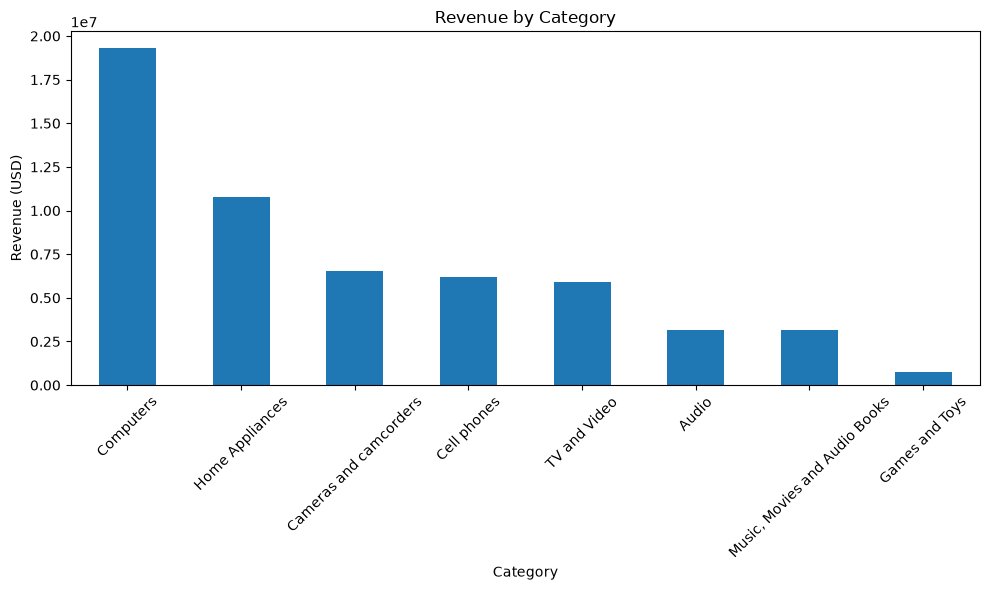

In [34]:
revenue_by_category.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Revenue by Category — Key Insight

**Computers** generated the highest revenue during the analyzed period, followed by **Home Appliances**.

**Games and Toys** generated the lowest revenue among all categories. The gap between **Computers** and the remaining categories is substantial, indicating a strong concentration of revenue in the computer segment.


## Revenue Trend Analysis

In [35]:
sales_products["Year"] = sales_products["Order Date"].dt.year

In [36]:
revenue_by_year = (
    sales_products
    .groupby("Year")["Revenue USD"]
    .sum()
)

revenue_by_year

Year
2016     6946793.56
2017     7421422.27
2018    12788960.66
2019    18264382.48
2020     9294632.14
2021     1039288.48
Name: Revenue USD, dtype: float64

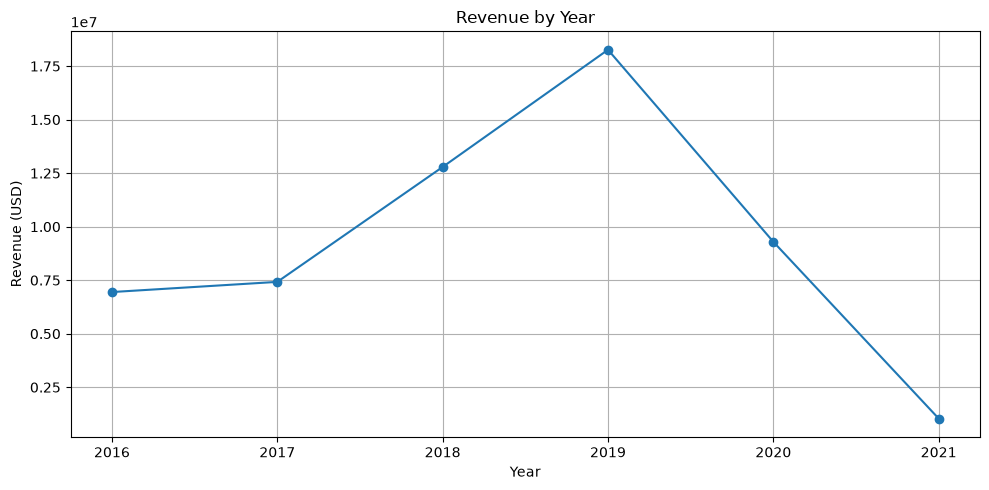

In [37]:
revenue_by_year.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")
plt.grid(True)
plt.tight_layout()

plt.show()

In [38]:
sales_products["Order Date"].min()

Timestamp('2016-01-01 00:00:00')

In [39]:
sales_products["Order Date"].max()

Timestamp('2021-02-20 00:00:00')

## Revenue by Year — Key Insight

Revenue increased from 2016 through 2019, reaching its highest level in 2019.

A significant decline is visible in 2020 compared with the previous year. The 2021 value should not be directly compared with full-year results because the dataset only includes observations through February 20, 2021.

In [40]:
## Monthly Revenue Trend

In [41]:
sales_products["YearMonth"] = (
    sales_products["Order Date"]
    .dt.to_period("M")
)

In [42]:
revenue_by_month = (
    sales_products
    .groupby("YearMonth")["Revenue USD"]
    .sum()
)

revenue_by_month.head()

YearMonth
2016-01    649918.78
2016-02    891098.30
2016-03    338407.36
2016-04    110591.63
2016-05    595986.18
Freq: M, Name: Revenue USD, dtype: float64

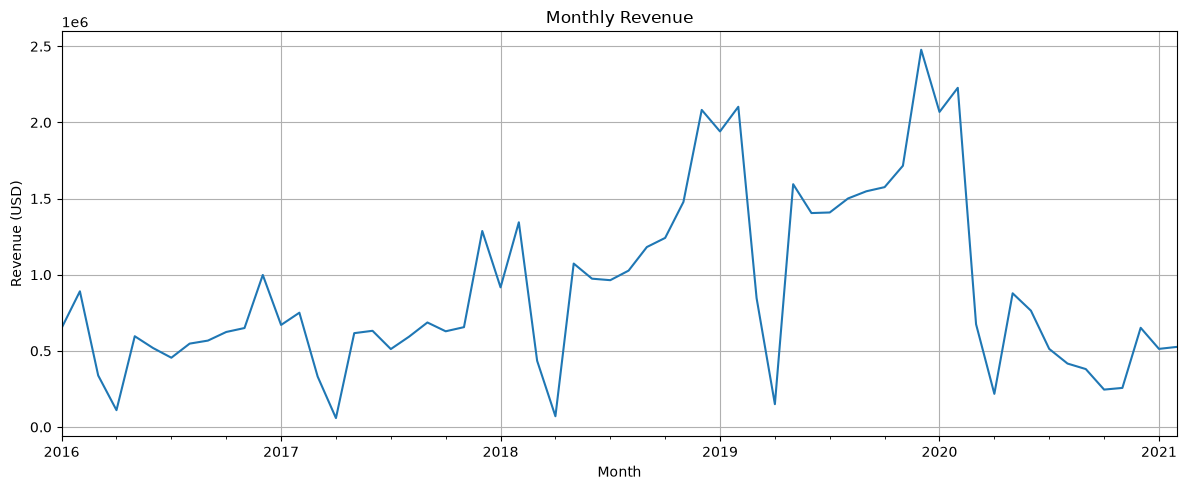

In [43]:
revenue_by_month.plot(
    kind="line",
    figsize=(12, 5)
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.grid(True)
plt.tight_layout()

plt.show()

## Monthly Revenue Trend — Key Insight

Monthly revenue generally increased between 2016 and 2019, with noticeable fluctuations throughout the period.

Several revenue peaks appear toward the end of 2018 and throughout 2019, while other periods show sharp declines. Revenue decreased substantially during 2020.

The 2021 data is incomplete and contains observations only through February 20, 2021, so it should be interpreted as a partial-year result.

## Seasonality Analysis

In [44]:
sales_products["Month"] = sales_products["Order Date"].dt.month

In [45]:
revenue_by_month_number = (
    sales_products
    .groupby("Month")["Revenue USD"]
    .sum()
)

revenue_by_month_number

Month
1     6759981.20
2     7842476.23
3     2625522.85
4      607334.05
5     4757983.80
6     4293036.54
7     3852415.81
8     4085169.32
9     4363863.61
10    4315027.44
11    4756059.88
12    7496608.86
Name: Revenue USD, dtype: float64

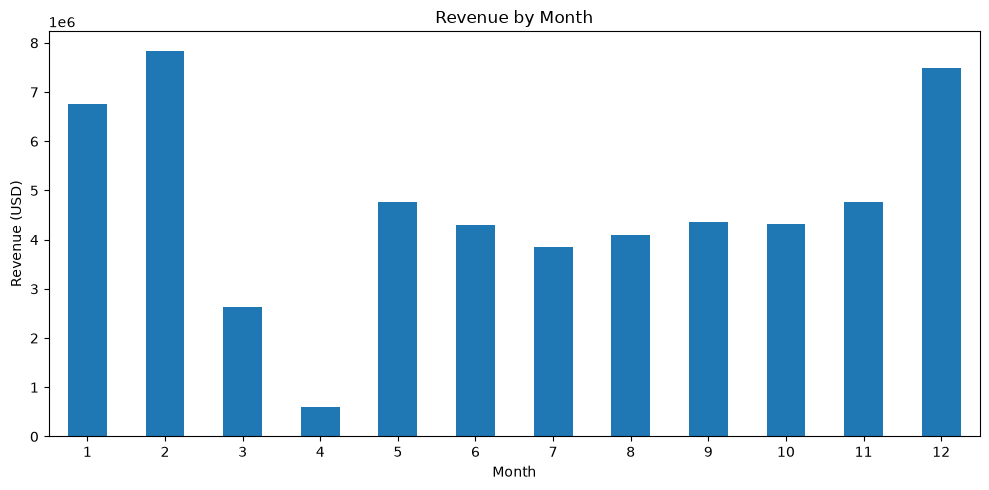

In [46]:
revenue_by_month_number.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## Revenue by Calendar Month — Initial Observation

When all available observations are aggregated by calendar month, February, December, and January show the highest accumulated revenue.

However, this comparison is affected by the partial 2021 data, which contains only January and February. For a more reliable seasonality assessment, the analysis should be restricted to complete years.

In [47]:
complete_years = sales_products[
    sales_products["Year"].between(2016,2020)
    ]

In [48]:
monthly_complete_years = (
    complete_years
    .groupby("Month")["Revenue USD"]
    .sum()
)
monthly_complete_years

Month
1     6246959.62
2     7316209.33
3     2625522.85
4      607334.05
5     4757983.80
6     4293036.54
7     3852415.81
8     4085169.32
9     4363863.61
10    4315027.44
11    4756059.88
12    7496608.86
Name: Revenue USD, dtype: float64

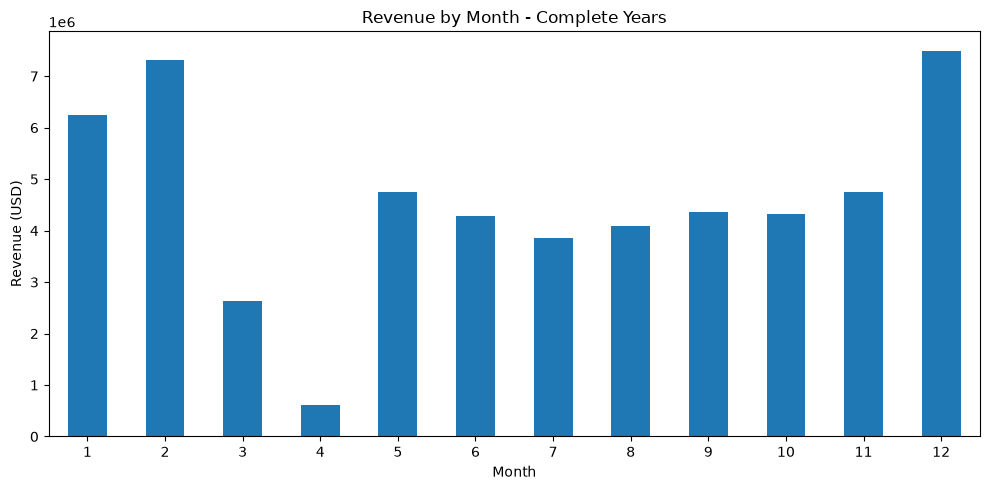

In [49]:
monthly_complete_years.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Revenue by Month - Complete Years")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## Seasonality — Complete Years

Considering only the complete years from 2016 to 2020, December generated the highest accumulated revenue, followed by February and January.

April recorded the lowest revenue, while March also performed below most other months.

This pattern suggests seasonality in the business, with stronger sales concentration near the beginning and end of the year.

## Product Performance Analysis

In [50]:
top_products_revenue = (
    sales_products
    .groupby("Product Name")["Revenue USD"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

Product Name
WWI Desktop PC2.33 X2330 Black                 505450.00
Adventure Works Desktop PC2.33 XD233 Silver    466089.00
Adventure Works Desktop PC2.33 XD233 Brown     464151.00
Adventure Works Desktop PC2.33 XD233 Black     447678.00
Adventure Works Desktop PC2.33 XD233 White     437019.00
WWI Desktop PC2.33 X2330 White                 424578.00
WWI Desktop PC2.33 X2330 Brown                 422740.00
Adventure Works 52" LCD HDTV X590 White        394398.64
Adventure Works 52" LCD HDTV X590 Black        374098.71
WWI Desktop PC2.33 X2330 Silver                360248.00
Name: Revenue USD, dtype: float64

In [51]:
top_products_quantity = (
    sales_products
    .groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_quantity

Product Name
WWI Desktop PC2.33 X2330 Black                550
WWI Desktop PC1.80 E1800 White                538
Adventure Works Desktop PC2.30 MD230 White    521
Adventure Works Desktop PC1.60 ED160 Black    521
Adventure Works Desktop PC1.80 ED180 Black    520
Adventure Works Desktop PC2.30 MD230 Black    514
WWI Desktop PC1.60 E1600 Black                509
WWI Desktop PC1.60 E1600 Silver               507
WWI Desktop PC1.80 E1801 Black                505
WWI Desktop PC1.60 E1600 Red                  505
Name: Quantity, dtype: int64

In [52]:
products_summary = (
    sales_products
    .groupby("Product Name")
    .agg(
        Units_Sold=("Quantity", "sum"),
        Revenue_USD=("Revenue USD", "sum")
    )
)

products_summary.head()

,Units_Sold,Revenue_USD
Product Name,,
A. Datum Advanced Digital Camera M300 Azure,31,5843.5
A. Datum Advanced Digital Camera M300 Black,34,6409.0
A. Datum Advanced Digital Camera M300 Green,41,7728.5
A. Datum Advanced Digital Camera M300 Grey,49,9236.5
A. Datum Advanced Digital Camera M300 Orange,46,8671.0


In [53]:
products_summary["Revenue_per_Unit"] = (
    products_summary["Revenue_USD"]/
    products_summary["Units_Sold"]
        )

In [54]:
products_summary.sort_values(
    "Revenue_USD",
    ascending=False
).head(10)

,Units_Sold,Revenue_USD,Revenue_per_Unit
Product Name,,,
WWI Desktop PC2.33 X2330 Black,550,505450.00,919.00
Adventure Works Desktop PC2.33 XD233 Silver,481,466089.00,969.00
Adventure Works Desktop PC2.33 XD233 Brown,479,464151.00,969.00
Adventure Works Desktop PC2.33 XD233 Black,462,447678.00,969.00
Adventure Works Desktop PC2.33 XD233 White,451,437019.00,969.00
WWI Desktop PC2.33 X2330 White,462,424578.00,919.00
WWI Desktop PC2.33 X2330 Brown,460,422740.00,919.00
"Adventure Works 52"" LCD HDTV X590 White",136,394398.64,2899.99
"Adventure Works 52"" LCD HDTV X590 Black",129,374098.71,2899.99


In [55]:
top_10_revenue = (
    products_summary
    .sort_values("Revenue_USD", ascending=False)
    .head(10)
)

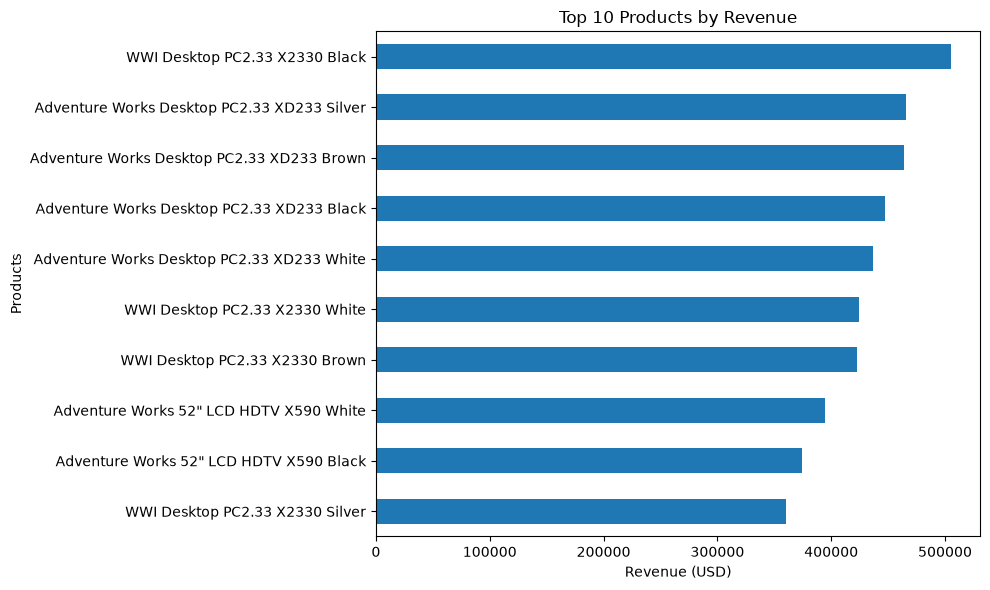

In [56]:
top_10_revenue["Revenue_USD"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Products")
plt.tight_layout()

plt.show()

## Product Performance — Key Insight

The highest-revenue products are predominantly desktop computers.

The **WWI Desktop PC2.33 X2330 Black generated** the highest revenue and also recorded the highest number of units sold among the products analyzed.

Some televisions also rank among the highest-revenue products despite much lower sales volumes. Their strong revenue performance is explained by a substantially higher revenue per unit.

This demonstrates that product revenue depends on both sales volume and unit price.

## Store and Sales Channel Analysis

In [57]:
stores = pd.read_csv(RAW_DATA_PATH / "Stores.csv")

In [58]:
stores.head()

,StoreKey,Country,State,Square Meters,Open Date
0,1,Australia,Australian Capital Territory,595.0,1/1/2008
1,2,Australia,Northern Territory,665.0,1/12/2008
2,3,Australia,South Australia,2000.0,1/7/2012
3,4,Australia,Tasmania,2000.0,1/1/2010
4,5,Australia,Victoria,2000.0,12/9/2015


In [59]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   StoreKey       67 non-null     int64  
 1   Country        67 non-null     str    
 2   State          67 non-null     str    
 3   Square Meters  66 non-null     float64
 4   Open Date      67 non-null     str    
dtypes: float64(1), int64(1), str(3)
memory usage: 4.6 KB


In [60]:
stores[stores["StoreKey"] == 0]

,StoreKey,Country,State,Square Meters,Open Date
66,0,Online,Online,NaN,1/1/2010


In [61]:
sales_full = sales_products.merge(
    stores,
    on="StoreKey",
    how="left"
)

In [62]:
sales_full.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,...,CategoryKey,Category,Revenue USD,Year,YearMonth,Month,Country,State,Square Meters,Open Date
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,...,4,Cameras and camcorders,68.00,2016,2016-01,1,Canada,Nunavut,1210.0,4/4/2015
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,...,4,Cameras and camcorders,854.00,2016,2016-01,1,Online,Online,NaN,1/1/2010
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,...,8,Home Appliances,665.94,2016,2016-01,1,Online,Online,NaN,1/1/2010
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,...,4,Cameras and camcorders,2254.00,2016,2016-01,1,Online,Online,NaN,1/1/2010
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,...,3,Computers,326.00,2016,2016-01,1,Online,Online,NaN,1/1/2010


In [63]:
sales_full.shape

(62884, 26)

In [64]:
sales_full["Sales Channel"] = sales_full["StoreKey"].apply(
    lambda x: "Online" if x == 0 else "Physical Store"
)

In [65]:
sales_full["Sales Channel"].value_counts()

Sales Channel
Physical Store    49719
Online            13165
Name: count, dtype: int64

In [66]:
revenue_by_channel = (
    sales_full
    .groupby("Sales Channel")["Revenue USD"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_channel

Sales Channel
Physical Store    44351154.96
Online            11404324.63
Name: Revenue USD, dtype: float64

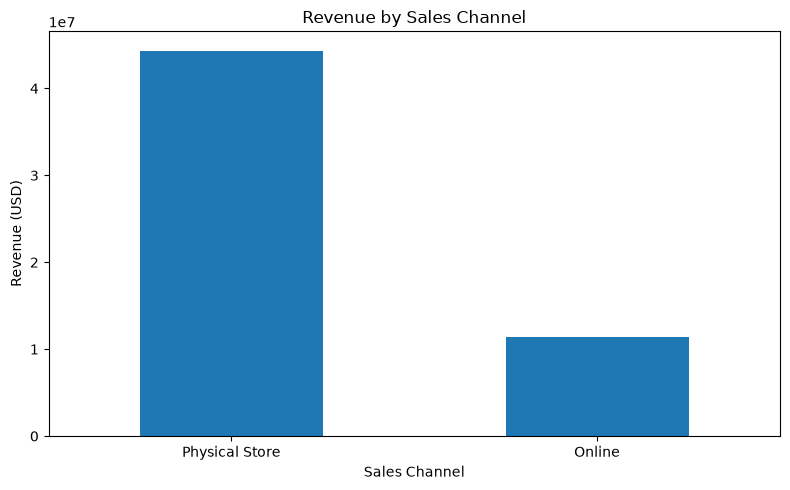

In [67]:
revenue_by_channel.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


In [68]:
channel_percentage = (
    revenue_by_channel / revenue_by_channel.sum() * 100
)

channel_percentage

Sales Channel
Physical Store    79.545823
Online            20.454177
Name: Revenue USD, dtype: float64

## Revenue by Sales Channel — Key Insight

Physical stores generated approximately 79.55% of total revenue, while the online channel contributed approximately 20.45%.

The business therefore remained strongly dependent on physical-store sales during the analyzed period. Nevertheless, online sales still represented a meaningful share of total revenue and are relevant for separate performance analysis.

## Geographic and Store Performance Analysis

In [69]:
physical_sales = sales_full[
    sales_full["StoreKey"] !=0
    ].copy()

In [70]:
revenue_by_country_physical = (
    physical_sales
    .groupby("Country")["Revenue USD"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_country_physical

Country
United States     23764425.86
United Kingdom     5749769.78
Germany            4246279.22
Canada             3611561.79
Australia          2099141.07
Italy              2059086.81
Netherlands        1591344.48
France             1229545.95
Name: Revenue USD, dtype: float64

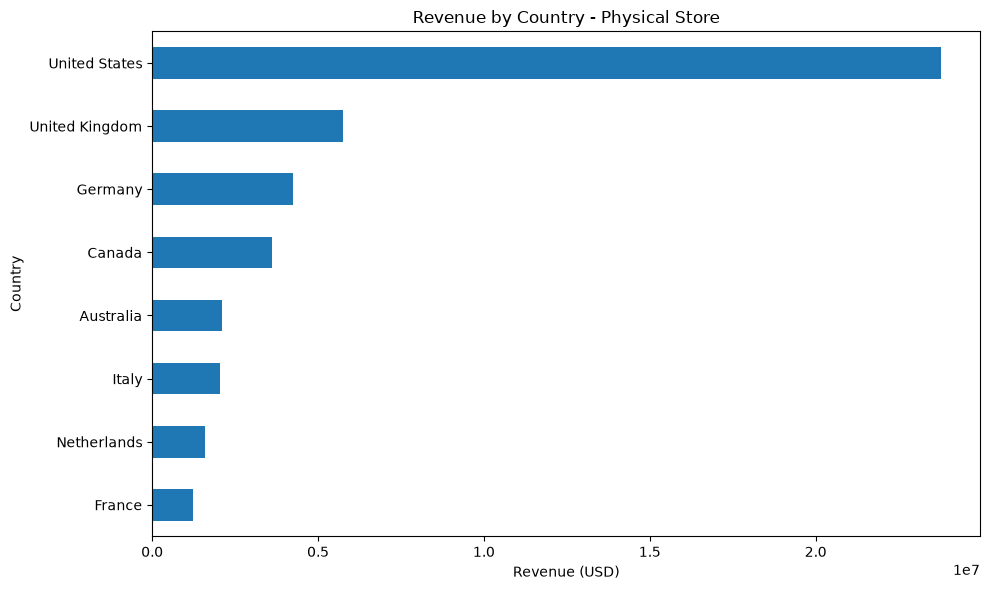

In [71]:
revenue_by_country_physical.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Revenue by Country - Physical Store")
plt.xlabel("Revenue (USD)")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

## Geographic Revenue — Scope

The geographic analysis considers physical stores only.

Online transactions were excluded because they do not represent a physical location. This prevents the online channel from being incorrectly interpreted as a country or geographic market.

In [72]:
top_stores = (
    physical_sales
    .groupby(
        ["StoreKey", "Country", "State"],
        as_index=False
    )["Revenue USD"]
    .sum()
    .sort_values(
        "Revenue USD",
        ascending=False
    )
    .head(10)
)

top_stores

,StoreKey,Country,State,Revenue USD
47,55,United States,Nevada,1417885.41
43,50,United States,Kansas,1394738.06
46,54,United States,Nebraska,1384396.24
6,9,Canada,Northwest Territories,1336150.06
49,57,United States,New Mexico,1325611.89
39,45,United States,Connecticut,1318787.92
51,61,United States,South Carolina,1305684.43
50,59,United States,Oregon,1302272.44
54,64,United States,Washington DC,1259350.98
37,43,United States,Alaska,1250255.14


In [73]:
top_stores["Store"] = (
    "Store " + 
    top_stores["StoreKey"].astype(str) +
    " - " +
    top_stores["State"]
)

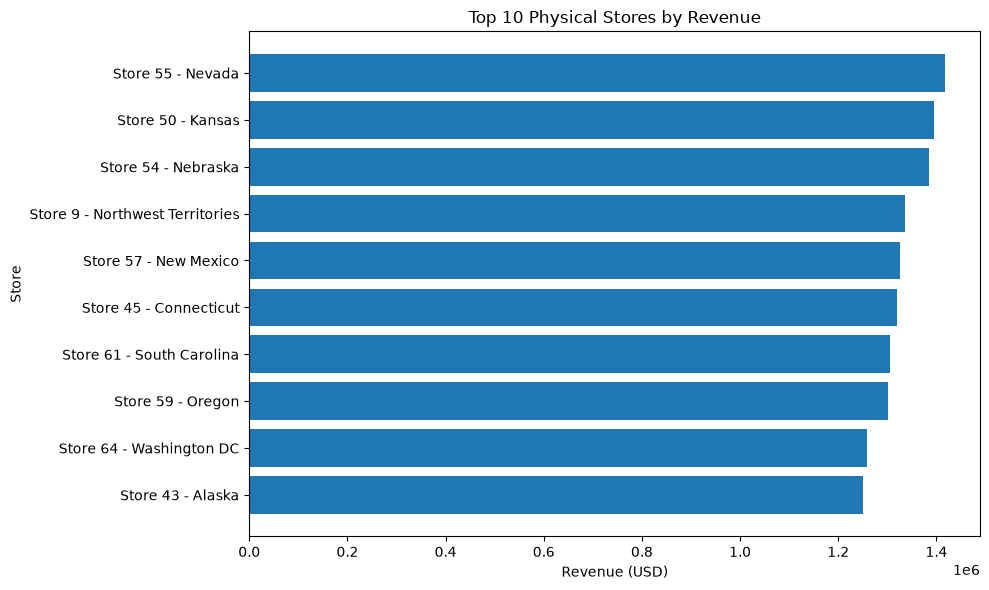

In [74]:
top_stores_plot = (
    top_stores
    .sort_values("Revenue USD")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_stores_plot["Store"],
    top_stores_plot["Revenue USD"]
)

plt.title("Top 10 Physical Stores by Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Store")
plt.tight_layout()

plt.show()

## Top Physical Stores — Key Insight

The store located in Nevada generated the highest revenue among the physical stores analyzed.

The United States has a strong presence among the best-performing locations, accounting for 9 of the top 10 stores by revenue.

The only store outside the United States in the top 10 is located in Northwest Territories, Canada.

## Business KPIs

In [75]:
total_revenue = sales_full["Revenue USD"].sum()
total_orders = sales_full["Order Number"].nunique()
total_units = sales_full["Quantity"].sum()
total_customers = sales_full["CustomerKey"].nunique()
average_order_value = total_revenue / total_orders

In [76]:
print(f"Total Revenue: US$ {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Units Sold: {total_units:,}")
print(f"Customers: {total_customers:,}")
print(f"Average Order Value: US${average_order_value:,.2f}")

Total Revenue: US$ 55,755,479.59
Total Orders: 26,326
Units Sold: 197,757
Customers: 11,887
Average Order Value: US$2,117.89


In [77]:
online_revenue = sales_full.loc[
    sales_full["Sales Channel"] == "Online",
    "Revenue USD"
    ].sum()

online_share = online_revenue / total_revenue * 100

print(f"Online Revenue Share: {online_share:.2f}%")

Online Revenue Share: 20.45%


## KPI Summary
During the analyzed period, the company generated approximately **US$55.8 million** in revenue across **26,326** orders and **197,757** units sold.

The dataset contains **11,887** unique customers, with an average order value of approximately **US$2,117.89**.

The online channel accounted for **20.45%** of total revenue, confirming that most revenue was generated by physical stores.

## Exporting the Processed Dataset for Power BI

In [78]:
sales_full.columns

Index(['Order Number', 'Line Item', 'Order Date', 'Delivery Date',
       'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code',
       'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD',
       'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category',
       'Revenue USD', 'Year', 'YearMonth', 'Month', 'Country', 'State',
       'Square Meters', 'Open Date', 'Sales Channel'],
      dtype='str')

In [79]:
PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)

output_path = PROCESSED_DATA_PATH / "sales_cleaned.csv"

sales_full.to_csv(
    output_path,
    index=False
)

In [80]:
test_export = pd.read_csv(output_path)

test_export.shape

(62884, 27)

In [81]:
test_export.info()

<class 'pandas.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order Number    62884 non-null  int64  
 1   Line Item       62884 non-null  int64  
 2   Order Date      62884 non-null  str    
 3   Delivery Date   13165 non-null  str    
 4   CustomerKey     62884 non-null  int64  
 5   StoreKey        62884 non-null  int64  
 6   ProductKey      62884 non-null  int64  
 7   Quantity        62884 non-null  int64  
 8   Currency Code   62884 non-null  str    
 9   Product Name    62884 non-null  str    
 10  Brand           62884 non-null  str    
 11  Color           62884 non-null  str    
 12  Unit Cost USD   62884 non-null  float64
 13  Unit Price USD  62884 non-null  float64
 14  SubcategoryKey  62884 non-null  int64  
 15  Subcategory     62884 non-null  str    
 16  CategoryKey     62884 non-null  int64  
 17  Category        62884 non-null  str    
 1

In [82]:
test_export.isnull().sum()

Order Number          0
Line Item             0
Order Date            0
Delivery Date     49719
CustomerKey           0
StoreKey              0
ProductKey            0
Quantity              0
Currency Code         0
Product Name          0
Brand                 0
Color                 0
Unit Cost USD         0
Unit Price USD        0
SubcategoryKey        0
Subcategory           0
CategoryKey           0
Category              0
Revenue USD           0
Year                  0
YearMonth             0
Month                 0
Country               0
State                 0
Square Meters     13165
Open Date             0
Sales Channel         0
dtype: int64

## Power BI Dashboard
The processed dataset exported in the previous step was used to build an interactive Power BI dashboard containing:
- Total Revenue
- Total Orders
- Units Sold
- Unique Customers
- Average Order Value
- Online Revenue Share
- Revenue by Year
- Revenue by Category
- Top 10 Products by Revenue
- Revenue by Sales Channel
- Interactive filters for Year, Country, and Sales Channel
The dashboard complements the Python analysis by providing an interactive business-facing view of the main findings.

# Conclusion

The Global Electronics Retailer generated approximately **US$55.8 million in total revenue**, across more than **26,000 orders** and nearly **198,000 units sold**.

**Computers** were the strongest product category by revenue, with a substantial lead over the remaining categories.

Revenue grew from 2016 to 2019 and reached its highest level in **2019**. A meaningful decline was observed in 2020, while 2021 should not be directly compared with full years because the dataset includes data only through February 20.

The complete-year seasonality analysis shows that **December** generated the highest accumulated monthly revenue, while March and especially April performed below most other months.

Desktop computers dominated the product rankings in both revenue and units sold. However, higher-priced products such as televisions were able to generate strong revenue with significantly lower sales volume.

Physical stores accounted for approximately **79.55% of total revenue**, compared with **20.45% from online sales**.

Geographically, the **United States** represented the strongest physical-store market and accounted for 9 of the 10 highest-revenue individual stores.

Overall, the analysis highlights the importance of the computer category, the continued dominance of physical retail, seasonal revenue patterns, and the concentration of strong store performance in the United States.